# Week 1: Returns and Risk
Pull ten years of daily data for both assets and compute daily returns from the **Adjusted Close** price.

In [ ]:
# Load your data from ../data/ (see the setup notebook)
import pandas as pd
TICKERS = ["NVDA", "DUK"]
NVDA = pd.read_csv(f"../data/{TICKERS[0]}.csv", index_col=0, parse_dates=True)
DUK = pd.read_csv(f"../data/{TICKERS[1]}.csv", index_col=0, parse_dates=True)

# NVDA
# Get NVDA Adjusted Close Col (daily prices)
nvda_prices = NVDA["Adj Close"]
# print(nvda_prices)

# Compute daily returns 
nvda_ret = nvda_prices.pct_change()
# print(nvda_ret)

# Drop NaN (removes rows that contain missing values and leaves real returns)
nvda_ret = nvda_ret.dropna()
# print(nvda_ret)

# DUK - run same steps as NVDA but all together
duk_ret = DUK["Adj Close"].pct_change().dropna()
# print(duk_ret)

# Combine nvda_ret and duk_ret into one DataFrame
returns = pd.concat({"NVDA": nvda_ret, "DUK": duk_ret}, axis=1).dropna()
# print(returns.head())
# print(returns.tail())

# Check dates
# print(NVDA.index.min(), NVDA.index.max())
# print(DUK.index.min(), DUK.index.max())


                NVDA       DUK
Date                          
2016-01-05  0.016064  0.007164
2016-01-06 -0.041350  0.002232
2016-01-07 -0.039645 -0.009185
2016-01-08 -0.021466 -0.002247
2016-01-11  0.001687  0.011120
                NVDA       DUK
Date                          
2025-12-24 -0.003171  0.005908
2025-12-26  0.010180 -0.002554
2025-12-29 -0.012124  0.002901
2025-12-30 -0.003613  0.001362
2025-12-31 -0.005545 -0.003994


## Visual
A single chart showing **cumulative log-scale returns** for both assets on the same axes.

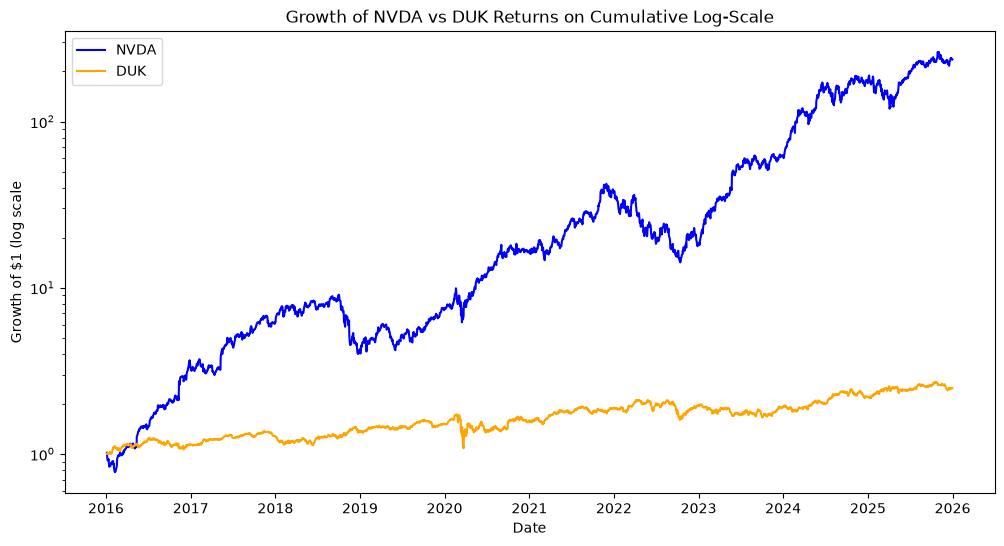

In [83]:
import matplotlib.pyplot as plt

# 1 + returns => growth multiplier, cumprod multiplies them (5.0 means 5x money)
cum = (1 + returns).cumprod()
# print(cum.head())
# print(cum.tail())

plt.figure(figsize=(12, 6))
plt.plot(cum.index, cum["NVDA"], color="blue", label="NVDA")
plt.plot(cum.index, cum["DUK"], color="orange", label="DUK")

plt.title("Growth of NVDA vs DUK Returns on Cumulative Log-Scale")
plt.xlabel('Date')
plt.ylabel('Growth of $1 (log scale')
plt.yscale("log")   # log scale

plt.legend()

plt.show()

## Table
Side-by-side comparison of **annualized return, annualized volatility, and maximum drawdown**.

In [ ]:
import numpy as np

# Annualized return - The yearly growth rate that would produce the same total result you actually got over the whole period
n_days = len(returns)
total_growth = cum.iloc[-1]
# print(total_growth) # Final value of $1 after 10 yrs
ann_return = (total_growth ** (252 / n_days)) - 1   # annualized return in decimal notation

# Annualized volatility - How much the asset’s returns swing around, expressed on a yearly scale (RIKS)
# The standard deviation of daily returns, scaled up to a year
ann_vol = returns.std() * np.sqrt(252)

# Maximum drawdown - The largest peak-to-trough drop over the whole period, measured as a percentage
# Buying at worst and selling at lowest
peak = cum.cummax()
drawdown = (cum / peak) -1
max_drawdown = drawdown.min()

summary = pd.DataFrame({
    "Annualized Return" : ann_return,
    "Annualized Volatility": ann_vol,
    "Maximum Drawdown" : max_drawdown
})

print(summary)

NVDA    236.199174
DUK       2.483640
Name: 2025-12-31 00:00:00, dtype: float64
      Annualized Return  Annualized Volatility  Maximum Drawdown
NVDA           0.729772               0.498938         -0.663351
DUK            0.095516               0.204144         -0.373719


## Context
Find the **five best and five worst days** for each asset, then look up the news to see what caused them.

In [ ]:
for ticker in ["NVDA", "DUK"]:
    print(f"--- { ticker}: 5 best days ---")
    print(returns[ticker].nlargest(5))  # .nlargest/smallest returns (n) largest date + #
    print(f"--- {ticker}: 5 worst days ---")
    print(returns[ticker].nsmallest(5))

---NVDA: 5 best days ---
Date
2016-11-11    0.298067
2023-05-25    0.243696
2025-04-09    0.187227
2017-05-10    0.178260
2020-03-24    0.171564
Name: NVDA, dtype: float64
--- NVDA: 5 worst days ---
Date
2018-11-16   -0.187559
2020-03-16   -0.184521
2025-01-27   -0.169681
2019-01-28   -0.138245
2020-03-12   -0.122368
Name: NVDA, dtype: float64
---DUK: 5 best days ---
Date
2020-03-17    0.123009
2020-03-24    0.114575
2020-03-26    0.086735
2020-09-30    0.074627
2020-04-06    0.068798
Name: DUK, dtype: float64
--- DUK: 5 worst days ---
Date
2020-03-12   -0.115021
2020-03-16   -0.107147
2020-03-20   -0.088608
2020-03-18   -0.078140
2020-03-23   -0.062134
Name: DUK, dtype: float64


| Asset | Date | Return | What happened |
|---|---|---|---|
| NVDA | 2016-11-11 | +29.8% | After the market closed on 11/10/2016, NVDA's Q3 Fiscal Year 2017 earnings showed a quarterly revenue of $2.00 billion (a 54% year-over-year increase), that far exceeded Wall Street's expectations of around $1.69 billion. And adjusted earnings per share surged 104% to $0.94, from rough estimates of $0.57 per share. |
| NVDA | 2018-11-16 | -18.8% | NVDA reported earnings on 11/15 after the close and gave weak Q4 guidance, which was lower than what analysts anticipated. Additionally, known as the "crypto hangover", where a bunch of crypto miners bought up massive quantities of NVDA products, and when crypto prices collapsed in 2018, demand from the miners disappeared. These miners then flooded the secondhand market with cheap, used GPUs that left NVDA's supply chain with severe overinventory. |
| DUK | 2020-03-17 | +12.3% | During the initial shock of the COVID-19 pandemic market crash, a combination of unprecedented central bank and fiscal policy interventions (the Federal Reserve's emergency credit lines and the White House's $1 trillion stimulus proposal  stabilized frozen credit markets and reversed the nationwide panic-selling from the previous day) and flight to safety (sell riskier assets and buy safer options), leading many to buy DUK. |
| DUK | 2020-03-12 | -11.5% | Due to the declaration of the global pandemic COVID-19, DUK fell with the broad market selloff. |
<!-- | | | | | -->


## The Paragraph
> **Which asset is actually riskier, and does taking on that extra risk result in a higher return?**

NVDA is riskier asset and taking on that extra risk did result in a higher return for this case. It's annualized volatility was 49.9% compared to DUK's 20.4%, and it's maximum drawdown reached -66.3% compared DUK's -37.4%. Additionally, NVDA's best day returned +29.8%, but it's worst day was also -18.8%, while as DUK had closer numbers of +12.3% on it's best day, and -11.5% on it.s worst day. However this risk did in fact pay off as NVDA's annualized return was 73.0%, where as DUK's is 9.55%, so $1 grew to a final value of $236.20 for NVDA versus, DUK's $2.48. Therefore, although NVDA is the riskier asset, that extra risk resulted in a higher return. Though this doesn't necessarily mean higher risk always pays out.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 1: returns and risk"
git push
```